Import thư viện và đọc dữ liệu

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Đọc dữ liệu California Housing
df = pd.read_csv("../data/california_housing.csv")

print("Kích thước dữ liệu:", df.shape)
display(df.head())
print("Số giá trị thiếu mỗi cột:")
print(df.isna().sum())
display(df.describe())

Kích thước dữ liệu: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Số giá trị thiếu mỗi cột:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


EDA

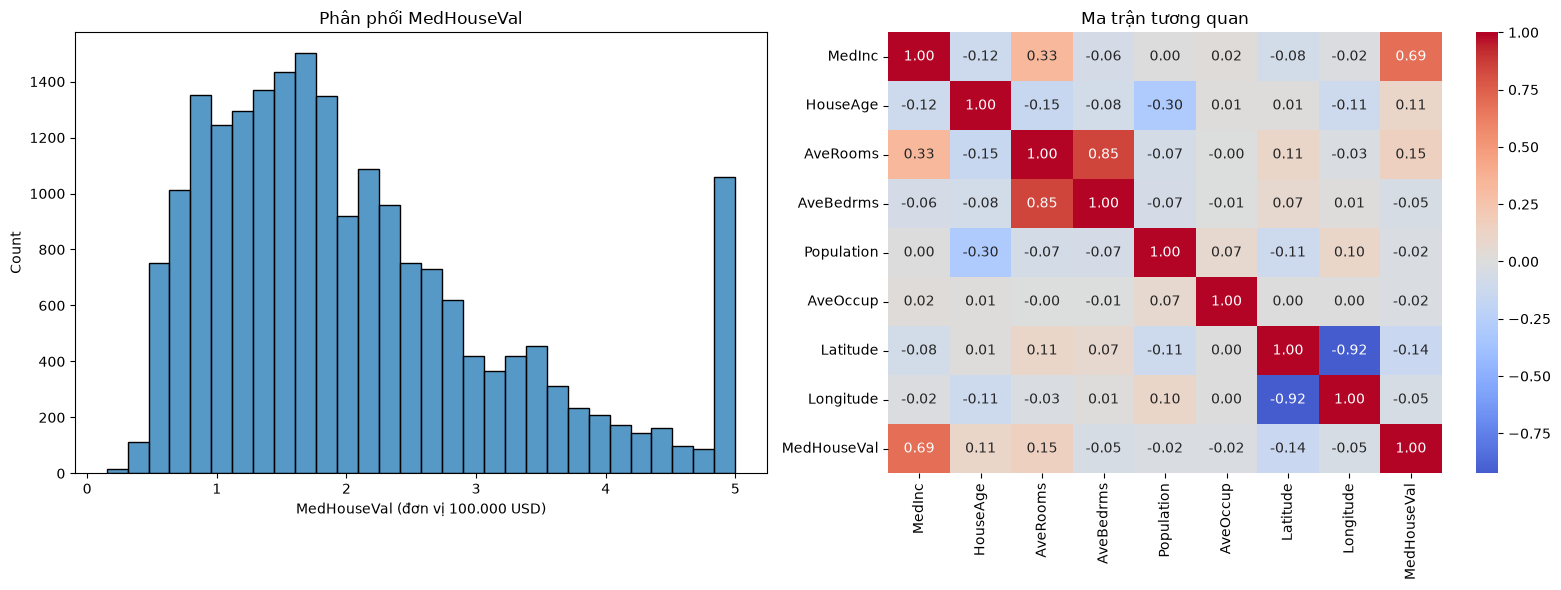

In [9]:
# Khám phá phân phối biến mục tiêu và tương quan giữa các biến
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(data=df, x="MedHouseVal", bins=30, ax=axes[0])
axes[0].set_title("Phân phối MedHouseVal")
axes[0].set_xlabel("MedHouseVal (đơn vị 100.000 USD)")

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Ma trận tương quan")

plt.tight_layout()
plt.savefig("figures/eda.png", dpi=300, bbox_inches="tight")
plt.show()

Tách X,Y .Chia dữ liệu 80% train 20% test

In [10]:
# Tách đặc trưng và biến mục tiêu
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]
X = df[features]
y = df["MedHouseVal"]

# Chia dữ liệu thành tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)

Kích thước X_train: (16512, 8)
Kích thước X_test: (4128, 8)


Huấn luyện cây quyết định

In [11]:
# Huấn luyện cây quyết định không giới hạn độ sâu làm baseline
baseline_model = DecisionTreeRegressor(random_state=42)
baseline_model.fit(X_train, y_train)

print(f"R2 trên tập train: {baseline_model.score(X_train, y_train):.4f}")
print(f"R2 trên tập test:  {baseline_model.score(X_test, y_test):.4f}")

R2 trên tập train: 1.0000
R2 trên tập test:  0.6228


Tìm tham số siêu tốc tốt nhất

In [12]:
# Tìm siêu tham số tốt nhất bằng GridSearchCV
param_grid = {
    "max_depth": [5, 8, 10, 15],
    "min_samples_leaf": [10, 20, 30, 50]
}
grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)
grid_search.fit(X_train, y_train)

print("Tham số tốt nhất:", grid_search.best_params_)

Tham số tốt nhất: {'max_depth': 15, 'min_samples_leaf': 20}


So sánh baseline và mô hình tốt nhất trên tập train/test

In [13]:
models = [
    ("Baseline", baseline_model),
    ("Tuned", grid_search.best_estimator_)
]
datasets = [("Train", X_train, y_train), ("Test", X_test, y_test)]
results = []

for model_name, model in models:
    for split_name, X_split, y_split in datasets:
        y_pred = model.predict(X_split)
        results.append({
            "Mô hình": model_name,
            "Tập dữ liệu": split_name,
            "MAE": mean_absolute_error(y_split, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_split, y_pred)),
            "R2": r2_score(y_split, y_pred)
        })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Mô hình,Tập dữ liệu,MAE,RMSE,R2
0,Baseline,Train,4.217126e-17,3.017601e-16,1.000000
1,Baseline,Test,4.541712e-01,7.030332e-01,0.622823
2,Tuned,Train,3.384015e-01,5.055415e-01,0.808815
3,Tuned,Test,4.040663e-01,5.978641e-01,0.727229


Trực quan hóa tầm quan trọng đặc trưng và dự đoán trên tập test

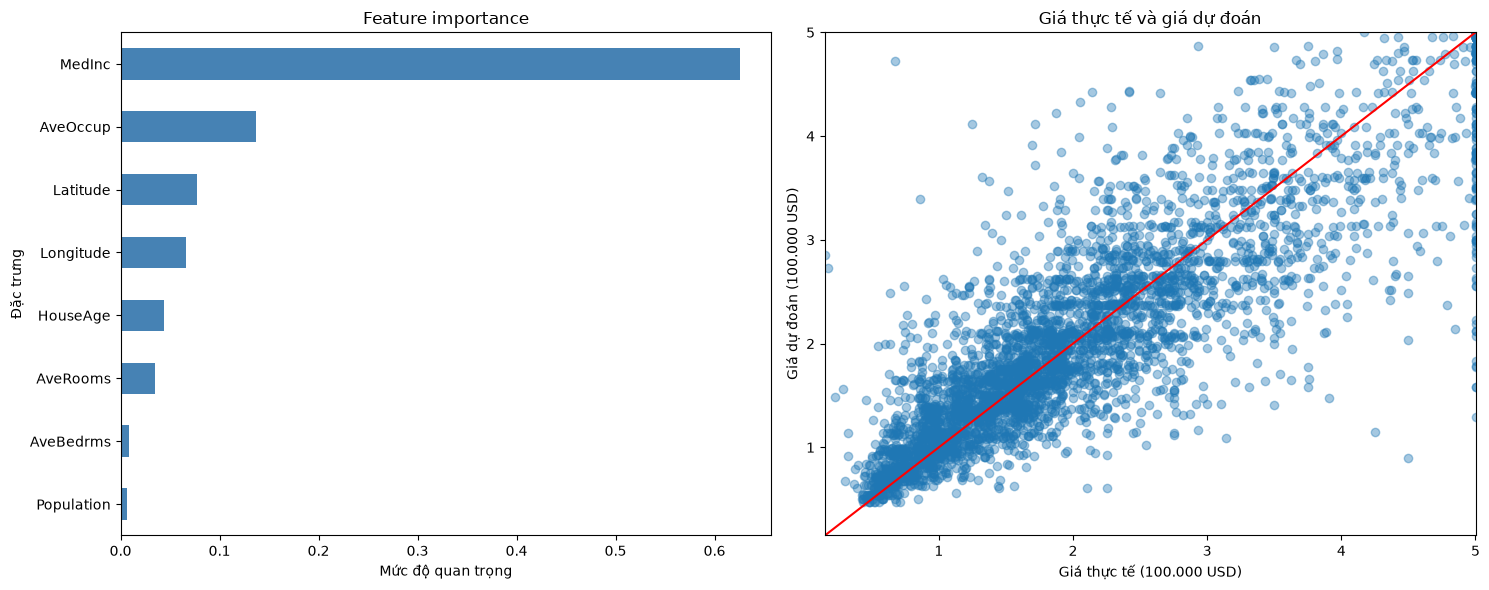

In [14]:
best_model = grid_search.best_estimator_
importance = pd.Series(best_model.feature_importances_, index=features).sort_values()
y_test_pred = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
importance.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Feature importance")
axes[0].set_xlabel("Mức độ quan trọng")
axes[0].set_ylabel("Đặc trưng")

axes[1].scatter(y_test, y_test_pred, alpha=0.4)
value_min = min(y_test.min(), y_test_pred.min())
value_max = max(y_test.max(), y_test_pred.max())
axes[1].plot([value_min, value_max], [value_min, value_max], color="red")
axes[1].set_title("Giá thực tế và giá dự đoán")
axes[1].set_xlabel("Giá thực tế (100.000 USD)")
axes[1].set_ylabel("Giá dự đoán (100.000 USD)")
axes[1].set_xlim(value_min, value_max)
axes[1].set_ylim(value_min, value_max)

plt.tight_layout()
plt.savefig("figures/result.png", dpi=300, bbox_inches="tight")
plt.show()